# Notebook 01 · Cadrage, audit des fuites, EDA, variables, split

**Question.** Chaque fin de mois, le Nikkei 225 va-t-il monter le mois suivant ? Et pour un investisseur en euros qui achète, la couverture du yen paie-t-elle ?

Ce notebook prépare la table de modélisation : il cadre le problème, vérifie par du code qu'aucune fuite n'entre dans les données, explore la période, construit les variables et découpe le temps en trois blocs.

| Section | Contenu | Cours |
|---|---|---|
| 1 | Cadrage : les cinq questions | S1, L1 |
| 2 | Audit des fuites | S1 |
| 3 | Exploration (EDA) | S1, L2 |
| 4 | Variables construites | énoncé (exigence 2), S3, L2 |
| 5 | Split chronologique | S1, S8 |
| 6 | Références sans compétence | S1, S7, S8 |

Entrée : `data/dataset_monthly.csv` (notebooks de collecte V1 et V2). Sortie : `data/processed/dataset_model.csv`.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, NullFormatter
import yaml
from scipy import stats
from sklearn.metrics import accuracy_score, average_precision_score, brier_score_loss, f1_score, log_loss

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CFG = yaml.safe_load(open(ROOT / "config.yaml"))
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)
S = {k: pd.Timestamp(v) for k, v in CFG["split"].items()}

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})

def axe_log_lisible(ax, fmt="{:,.0f}"):
    # Échelle log avec des nombres ordinaires sur l'axe (pas de 10^4)
    ax.set_yscale("log")
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: fmt.format(v).replace(",", " ")))
    ax.yaxis.set_minor_formatter(NullFormatter())

raw = pd.read_csv(ROOT / CFG["data"]["monthly"], parse_dates=["date"]).set_index("date")
dico = pd.read_csv(ROOT / CFG["data"]["dictionary"])
print(f"{len(raw)} mois, de {raw.index[0]:%Y-%m} à {raw.index[-1]:%Y-%m}, {raw.shape[1]} colonnes")

202 mois, de 2010-01 à 2026-10, 77 colonnes


## 1. Cadrage : les cinq questions (S1)

| Question (S1) | Réponse pour le projet |
|---|---|
| **Unit** : l'unité de décision | un mois *t*, décidé à la dernière séance de Tokyo du mois ; une ligne = un mois |
| **Target + horizon** | *y* = 1 si le Nikkei (en yens) monte le mois suivant ; seconde cible : ne pas couvrir le yen était-il mieux le mois suivant ? |
| **Cheating** : les fuites | surtout la fuite temporelle : chaque variable doit être connue à la clôture de Tokyo du dernier jour du mois |
| **Choose the split** | chronologique, puis `TimeSeriesSplit` pour la validation croisée (« train on past, validate on future ») |
| **No-skill baseline** | « toujours hausse » et « toujours couvert » ; la régression logistique sert de baseline simple, plus forte |

**Lecture de L1 (Mitchell).** T = prédire la hausse du mois suivant ; E = l'historique mensuel depuis 2010 ; P = log-loss, F1 de la classe baisse et rendement en euros de la décision.

**Le modèle estime, la règle décide (S1).** Acheter, rester neutre et vendre ne sont pas des faits observés mais des décisions. On prédit donc un fait (la hausse), puis une règle de seuils transforme la probabilité en action (notebook 03). C'est aussi pourquoi on garde deux classifications binaires plutôt qu'une classification à trois classes.

**Classe positive des métriques (S7).** L'événement rare et coûteux : la **baisse** pour le Nikkei, le **yen fort** (ne pas couvrir était mieux) pour la couverture.

## 2. Audit des fuites (S1)

Une fuite rend la validation optimiste : le modèle y utilise une information qu'il n'aura pas au moment de décider. Chaque point ci-dessous est vérifié par du code, pas seulement affirmé.

**2a et 2b.** La cible du mois *t* doit être le rendement du mois *t + 1*, et l'identité de la couverture (couvert − non couvert = portage − rendement du yen) doit tenir.

In [2]:
df = raw.copy()
a_connaitre = df["target_rn_next"].isna()
df["y_baisse"] = (df["target_rn_next"] <= 0).astype(float)
df["y_non_couvert"] = (df["carry_1m"] - df["target_fx_next"] <= 0).astype(float)
df.loc[a_connaitre, ["y_baisse", "y_non_couvert"]] = np.nan

ecart_cible = (df["target_rn_next"] - df["n225_ret_1m"].shift(-1)).abs().max()
ecart_prix = (df["target_rn_next"] - (df["n225_close"].shift(-1) / df["n225_close"] - 1)).abs().max()
ecart_couv = ((df["target_reur_hedged_next"] - df["target_reur_unhedged_next"])
              - (df["carry_1m"] - df["target_fx_next"])).abs().max()

print(f"cible du mois t  vs  rendement du mois t+1 : écart max {ecart_cible:.1e}")
print(f"cible du mois t  vs  prix de t et t+1      : écart max {ecart_prix:.1e}  (arrondi des prix dans le CSV)")
print(f"couvert - non couvert  vs  C_t - E_t+1     : écart max {ecart_couv:.1e}")
assert ecart_cible < 1e-9 and ecart_prix < 1e-5 and ecart_couv < 1e-5

cible du mois t  vs  rendement du mois t+1 : écart max 0.0e+00
cible du mois t  vs  prix de t et t+1      : écart max 5.7e-06  (arrondi des prix dans le CSV)
couvert - non couvert  vs  C_t - E_t+1     : écart max 7.3e-07


**2c. Aucune cible parmi les variables explicatives, et une seule ligne à prédire.**

In [3]:
FEATURES = [c for groupe in ["news", "price", "macro", "fx"] for c in CFG["features"][groupe]]
REGIME = CFG["features"]["regime"]
CIBLES = [c for c in df.columns if c.startswith("target_")] + ["y_baisse", "y_non_couvert"]
assert not set(FEATURES + REGIME) & set(CIBLES), "une cible est dans les variables"

print("variables envoyées au modèle :", FEATURES)
print("variables du régime k-means  :", REGIME)
print("mois sans cible (à prédire)  :", df.index[a_connaitre].strftime("%Y-%m").tolist())

variables envoyées au modèle : ['news_attention_6m', 'news_sent_w', 'news_dispo', 'n225_mom_12m', 'n225_mom_3m', 'n225_vol_ewma', 'd_jgb10y_bp', 'tankan_large_manuf', 'carry_1m', 'eurjpy_rvol_1m']
variables du régime k-means  : ['n225_vol_ewma', 'n225_ret_1m', 'vix']
mois sans cible (à prédire)  : ['2026-10']


**2d. Décalages de publication.** Ils ont été appliqués sur les données quotidiennes, avant l'agrégation mensuelle (notebook V1, étape 14) : chaque série est décalée jusqu'à être connue avant la clôture de Tokyo (15h30, soit 6h30 UTC). Les colonnes mensuelles en héritent. Le dictionnaire des variables documente ces décalages :

In [4]:
sources = ["vix", "us10y", "jgb10y", "tona", "eur_overnight", "eurjpy", "tankan_large_manuf", "cpi_all_yoy", "n225_vol_ewma"]
quotidien = dico[dico["fichier"].str.contains("news_v2")].drop_duplicates("colonne").set_index("colonne")
quotidien.loc[sources, ["decalage", "definition"]]

,decalage,definition
colonne,,
vix,veille calendaire,"VIX (CBOE), niveau"
us10y,veille calendaire,"Rendement à 10 ans us10y, en %"
jgb10y,1 séance,"Rendement JGB 10 ans, en % (MOF)"
tona,1 séance,"TONA, taux au jour le jour du yen, en % (BoJ)"
eur_overnight,2 séances,"Taux au jour le jour de l'euro, en % (EONIA pu..."
eurjpy,veille calendaire,Taux de change eurjpy (yens pour une unité de ...
tankan_large_manuf,aucun (connu avant la clôture),"Tankan, DI des grandes entreprises : large_man..."
cpi_all_yoy,aucun (connu avant la clôture),"CPI Japon : all_yoy (dernière publication, e-S..."
n225_vol_ewma,aucun (connu avant la clôture),"Volatilité EWMA du Nikkei (lambda = 0,94), ann..."


**2e. Les séries macro sont datées à leur publication, pas à la période qu'elles décrivent.** Le Tankan d'un trimestre est rendu disponible 5 jours après la fin du trimestre. Il ne doit donc changer qu'en fin de janvier, avril, juillet et octobre. S'il changeait en mars, on utiliserait une enquête avant sa publication.

In [5]:
change = df["tankan_large_manuf"].diff().fillna(0) != 0
mois_changement = df.index[change].month.value_counts().sort_index()
print("mois de l'année où le Tankan change :", mois_changement.to_dict())
assert set(mois_changement.index) <= {1, 4, 7, 10}

mois de l'année où le Tankan change : {1: 13, 4: 15, 7: 16, 10: 15}


**Bilan de l'audit.** La cible est bien celle du mois suivant, aucune cible n'entre dans les variables, les séries macro changent à leur date de publication, et la dernière ligne (octobre 2026) est la seule sans cible : c'est la ligne à prédire, jamais un exemple d'entraînement. Les variables construites (section 4) passent un test supplémentaire : on vérifie qu'elles ne changent pas quand on coupe le futur.

## 3. Exploration (EDA)

**3a. Disponibilité des variables.** Les variables de prix, de taux et de change existent depuis 2010 ; les news commencent en janvier 2017.

In [6]:
BASE = ["n225_mom_12m", "n225_mom_3m", "n225_vol_ewma", "n225_ret_1m", "vix", "d_jgb10y_bp", "tankan_large_manuf",
        "carry_1m", "eurjpy_rvol_1m", "news_japan_n_1m", "news_boj_n_1m", "news_japan_sent_1m", "news_boj_sent_1m"]
periode = df.loc[S["start"]:]
dispo = pd.DataFrame({
    "premier mois": [periode[c].first_valid_index().strftime("%Y-%m") for c in BASE],
    "mois manquants": periode[BASE].isna().sum().values,
}, index=BASE)
dispo

,premier mois,mois manquants
n225_mom_12m,2010-02,0
n225_mom_3m,2010-02,0
n225_vol_ewma,2010-02,0
n225_ret_1m,2010-02,0
vix,2010-02,0
d_jgb10y_bp,2010-02,0
tankan_large_manuf,2010-02,0
carry_1m,2010-02,0
eurjpy_rvol_1m,2010-02,0
news_japan_n_1m,2017-01,83


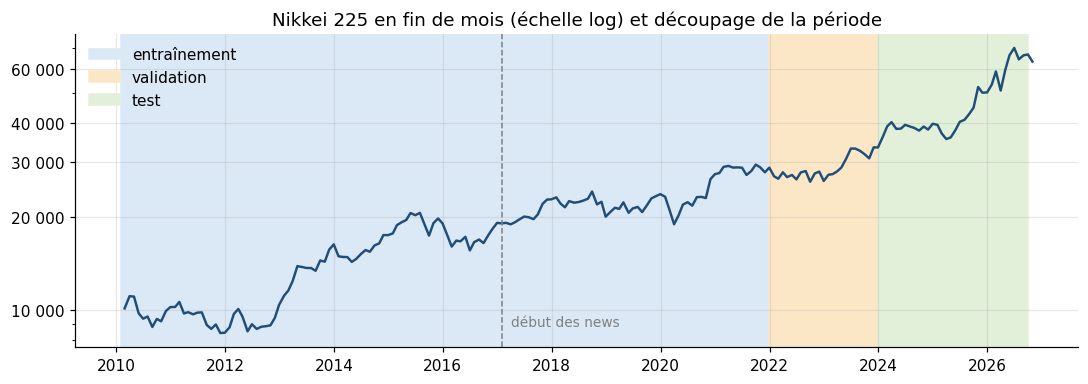

In [7]:
blocs = {"entraînement": (S["start"], S["train_end"]),
         "validation": (S["train_end"], S["validation_end"]),
         "test": (S["validation_end"], S["test_end"])}
couleurs = {"entraînement": "#dbe8f6", "validation": "#fbe7c6", "test": "#e2f0d9"}

fig, ax = plt.subplots(figsize=(10, 3.6))
for nom, (a, b) in blocs.items():
    ax.axvspan(a, b, color=couleurs[nom], label=nom, zorder=0)
ax.plot(periode.index, periode["n225_close"], color="#1f4e79", lw=1.6)
ax.axvline(pd.Timestamp("2017-01-31"), color="grey", ls="--", lw=1)
ax.text(pd.Timestamp("2017-03-31"), periode["n225_close"].min() * 1.05, "début des news", color="grey", fontsize=9)
axe_log_lisible(ax)
ax.set_yticks([10_000, 20_000, 30_000, 40_000, 60_000])
ax.set_title("Nikkei 225 en fin de mois (échelle log) et découpage de la période")
ax.legend(loc="upper left", frameon=False)
fig.tight_layout()
fig.savefig(FIG / "01_nikkei_split.png")
plt.show()

**3b. Les deux cibles, période par période.** La part de baisses fixe la référence de la PR-AUC (S7) ; le portage dit ce que coûte ou rapporte la couverture.

In [8]:
modele = df.loc[S["start"]:S["test_end"]]
sous_periodes = {"2010-2016 (sans news)": ("2010-02", "2016-12"), "2017-2021": ("2017-01", "2021-12"),
                 "validation 2022-2023": ("2022-01", "2023-12"), "test 2024-2026": ("2024-01", "2026-09")}
lignes = []
for nom, (a, b) in sous_periodes.items():
    s = modele.loc[a:b]
    lignes.append({"période": nom, "mois": len(s),
                   "rendement moyen du Nikkei (%/mois)": 100 * s["target_rn_next"].mean(),
                   "part de baisses": s["y_baisse"].mean(),
                   "part où ne pas couvrir était mieux": s["y_non_couvert"].mean(),
                   "portage moyen (%/an)": 1200 * s["carry_1m"].mean()})
pd.DataFrame(lignes).set_index("période").round(3)

,mois,rendement moyen du Nikkei (%/mois),part de baisses,part où ne pas couvrir était mieux,portage moyen (%/an)
période,,,,,
2010-2016 (sans news),83,0.907,0.410,0.494,0.114
2017-2021,60,0.693,0.367,0.433,-0.407
validation 2022-2023,24,1.340,0.417,0.292,1.714
test 2024-2026,33,1.899,0.364,0.394,2.193


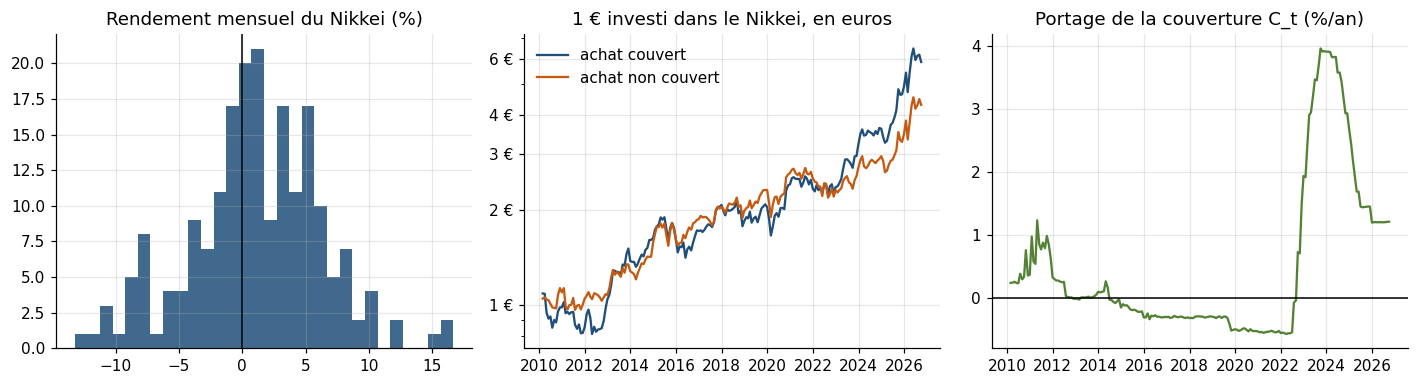

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
axes[0].hist(100 * modele["target_rn_next"], bins=30, color="#1f4e79", alpha=0.85)
axes[0].axvline(0, color="black", lw=1)
axes[0].set_title("Rendement mensuel du Nikkei (%)")

cumul = (1 + modele[["target_reur_hedged_next", "target_reur_unhedged_next"]]).cumprod()
axes[1].plot(cumul.index, cumul["target_reur_hedged_next"], color="#1f4e79", label="achat couvert")
axes[1].plot(cumul.index, cumul["target_reur_unhedged_next"], color="#c55a11", label="achat non couvert")
axe_log_lisible(axes[1], "{:.0f} €")
axes[1].set_yticks([1, 2, 3, 4, 6])
axes[1].set_title("1 € investi dans le Nikkei, en euros")
axes[1].legend(frameon=False)

axes[2].plot(modele.index, 1200 * modele["carry_1m"], color="#548235")
axes[2].axhline(0, color="black", lw=1)
axes[2].set_title("Portage de la couverture C_t (%/an)")
fig.tight_layout()
fig.savefig(FIG / "01_cibles_couverture.png")
plt.show()

## 4. Variables construites (exigence 2)

Trois variables de news sont construites à partir des comptes d'articles (*n<sup>J</sup>*, *n<sup>B</sup>* : thèmes Japon et BoJ) et de leur score FinBERT moyen (*s<sup>J</sup>*, *s<sup>B</sup>* = P(positif) − P(négatif)) :

$$A_t=\ln\left(n^J_t+n^B_t\right)-\frac{1}{6}\sum_{k=1}^{6}\ln\left(n^J_{t-k}+n^B_{t-k}\right),\qquad \bar s_t=\frac{n^J_t\,s^J_t+n^B_t\,s^B_t}{n^J_t+n^B_t},\qquad \text{news\_dispo}_t=\mathbb{1}\{A_t \text{ existe}\}$$

- **Volume anormal d'articles** *A<sub>t</sub>* : ce mois comparé à la moyenne des 6 mois précédents (au moins 3). C'est le signal news le plus informatif de l'analyse exploratoire (notebook `nikkei_news_prix`).
- **Sentiment pondéré** *s̄<sub>t</sub>* : le sentiment moyen du mois, chaque thème pesant son nombre d'articles.
- **Indicateur de news** : vaut 0 avant 2017. Les valeurs manquantes de *A<sub>t</sub>* et *s̄<sub>t</sub>* seront imputées dans la pipeline (étape 2) ; l'indicateur dit au modèle quand l'imputation a eu lieu.

Ces variables n'utilisent que le passé de chaque ligne : on peut donc les calculer avant le split. Le test ci-dessous le prouve : on les recalcule sur des données coupées en juin 2020, et elles doivent être identiques.

In [10]:
def variables_news(d):
    n_tot = (d["news_japan_n_1m"] + d["news_boj_n_1m"]).where(lambda n: n > 0)
    log_n = np.log(n_tot)
    out = pd.DataFrame(index=d.index)
    out["news_attention_6m"] = log_n - log_n.shift(1).rolling(6, min_periods=3).mean()
    out["news_sent_w"] = (d["news_japan_n_1m"] * d["news_japan_sent_1m"]
                          + d["news_boj_n_1m"] * d["news_boj_sent_1m"]) / n_tot
    out["news_dispo"] = out["news_attention_6m"].notna().astype(int)
    return out

complet = variables_news(df)
coupe = variables_news(df.loc[:"2020-06-30"])
assert np.allclose(complet.loc[:"2020-06-30"].to_numpy(), coupe.to_numpy(), equal_nan=True)
print("test sans regard vers le futur : réussi")

df[complet.columns] = complet
print("premier mois avec les variables de news :", df["news_attention_6m"].first_valid_index().strftime("%Y-%m"))

test sans regard vers le futur : réussi
premier mois avec les variables de news : 2017-04


**4b. Relation de chaque variable avec les deux cibles, sur l'entraînement seulement.** Corrélation de rang (Spearman) avec le rendement du mois suivant, et avec l'avantage de la couverture (*C<sub>t</sub>* − *E<sub>t+1</sub>*). C'est un repère, pas un résultat : avec si peu de mois, une corrélation doit dépasser environ 2/√n pour sortir du bruit.

*Limite à signaler dans le rapport.* Le choix des variables s'appuie sur l'analyse exploratoire du zip, faite sur 2017-2026, qui recouvre la validation et le test. Le tableau ci-dessous, lui, ne regarde que l'entraînement.

In [11]:
train = df.loc[S["start"]:S["train_end"]]
avantage_couverture = train["carry_1m"] - train["target_fx_next"]
lignes = []
for c in FEATURES:
    ok = train[c].notna() & (train[c].nunique() > 1)
    if train.loc[ok, c].nunique() < 2:
        continue
    a = stats.spearmanr(train.loc[ok, c], train.loc[ok, "target_rn_next"])
    b = stats.spearmanr(train.loc[ok, c], avantage_couverture[ok])
    lignes.append({"variable": c, "mois": int(ok.sum()), "seuil 2/√n": 2 / np.sqrt(ok.sum()),
                   "corr. rendement suivant": a.statistic, "p": a.pvalue,
                   "corr. avantage couverture": b.statistic, "p ": b.pvalue})
pd.DataFrame(lignes).set_index("variable").round(3)

,mois,seuil 2/√n,corr. rendement suivant,p,corr. avantage couverture,p
variable,,,,,,
news_attention_6m,57,0.265,-0.379,0.004,-0.108,0.426
news_sent_w,60,0.258,0.033,0.800,-0.028,0.831
news_dispo,143,0.167,-0.027,0.749,0.002,0.980
n225_mom_12m,143,0.167,-0.113,0.179,0.090,0.287
n225_mom_3m,143,0.167,-0.007,0.933,0.131,0.118
n225_vol_ewma,143,0.167,0.032,0.707,-0.094,0.263
d_jgb10y_bp,143,0.167,-0.114,0.176,-0.063,0.451
tankan_large_manuf,143,0.167,-0.056,0.504,-0.115,0.170
carry_1m,143,0.167,-0.012,0.890,-0.027,0.752


**4c. Variables corrélées entre elles (L2 de Maths, S3).** Deux variables qui disent presque la même chose rendent les coefficients instables. La pénalité Ridge les stabilise, et l'importance par permutation devra être lue avec ce piège en tête (S9).

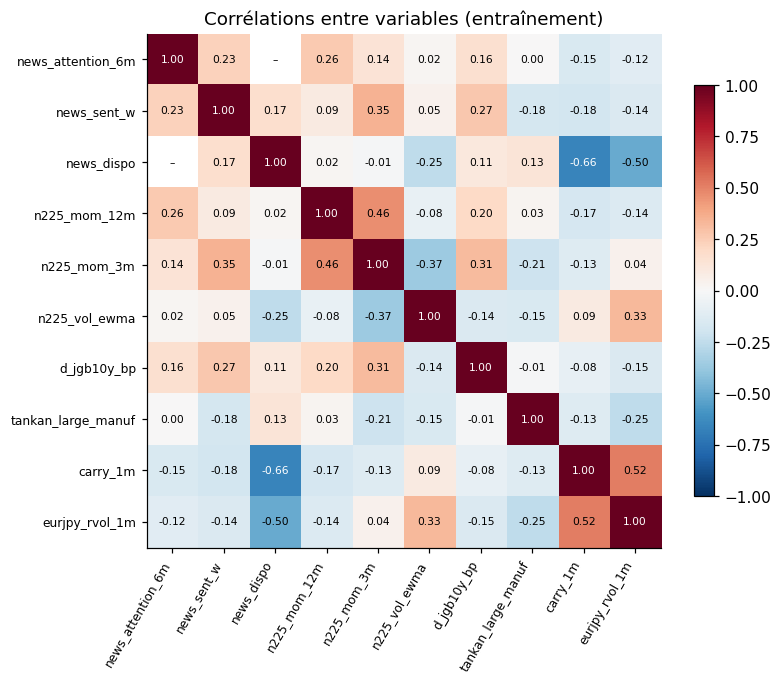

paires avec |r| > 0,6 :
news_dispo  carry_1m   -0.66


In [12]:
corr = train[FEATURES].corr()
fig, ax = plt.subplots(figsize=(7.5, 6.2))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(FEATURES)), FEATURES, fontsize=8)
for i in range(len(FEATURES)):
    for j in range(len(FEATURES)):
        valeur = corr.iloc[i, j]
        ax.text(j, i, "–" if np.isnan(valeur) else f"{valeur:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(corr.iloc[i, j]) > 0.6 else "black")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Corrélations entre variables (entraînement)")
fig.tight_layout()
fig.savefig(FIG / "01_correlations.png")
plt.show()

paires = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
print("paires avec |r| > 0,6 :")
print(paires[paires.abs() > 0.6].round(2).to_string())

## 5. Split chronologique (S1, S8)

Trois blocs dans l'ordre du temps, jamais mélangés. La validation sert au choix du modèle et à juger la calibration. Note ajoutée après la revue finale : la calibration a finalement été apprise sur les prédictions hors fold, et les seuils sur les coûts de l'entraînement (notebook 03). Le test n'est utilisé qu'une fois, à la fin.

In [13]:
df["bloc"] = np.select(
    [df.index < S["start"], df.index <= S["train_end"], df.index <= S["validation_end"], df.index <= S["test_end"]],
    ["hors période", "entraînement", "validation", "test"], default="à prédire")

resume = (df[df["bloc"] != "hors période"]
          .groupby("bloc", sort=False)
          .agg(début=("bloc", lambda s: s.index.min().strftime("%Y-%m")),
               fin=("bloc", lambda s: s.index.max().strftime("%Y-%m")),
               mois=("bloc", "size"),
               part_baisses=("y_baisse", "mean"),
               part_non_couvert_mieux=("y_non_couvert", "mean"),
               part_mois_avec_news=("news_dispo", "mean")))
display(resume.round(3))

attendu = {"entraînement": 143, "validation": 24, "test": 33, "à prédire": 1}
assert resume["mois"].to_dict() == attendu, resume["mois"].to_dict()

,début,fin,mois,part_baisses,part_non_couvert_mieux,part_mois_avec_news
bloc,,,,,,
entraînement,2010-02,2021-12,143,0.392,0.469,0.399
validation,2022-01,2023-12,24,0.417,0.292,1.000
test,2024-01,2026-09,33,0.364,0.394,1.000
à prédire,2026-10,2026-10,1,NaN,NaN,1.000


In [14]:
GARDER = (FEATURES + [c for c in REGIME if c not in FEATURES]
          + ["y_baisse", "y_non_couvert", "target_up_next", "target_rn_next", "target_fx_next",
             "target_reur_unhedged_next", "target_reur_hedged_next", "target_short_eur_next",
             "eur_overnight", "boj_meeting_next_month", "n225_close", "bloc"])
table = df.loc[df["bloc"] != "hors période", GARDER]
sortie = ROOT / CFG["data"]["model_table"]
sortie.parent.mkdir(parents=True, exist_ok=True)
table.to_csv(sortie)
print(f"{sortie.relative_to(ROOT)} : {table.shape[0]} mois x {table.shape[1]} colonnes")

data/processed/dataset_model.csv : 201 mois x 24 colonnes


## 6. Références sans compétence (S1, S7, S8)

Le plancher que chaque modèle devra battre. Le modèle constant annonce, chaque mois, la fréquence observée sur l'entraînement. Le calcul n'utilise aucun modèle : regarder la fréquence du test n'est pas une évaluation.

- **« toujours négatif »** : jamais de baisse annoncée (Nikkei) ou toujours couvert (couverture). Bonne accuracy, F1 nul : le piège de S7.
- **« toujours positif »** : son F1 est la vraie barre à dépasser.
- **Modèle constant** : sa log-loss et son Brier (S8 : BS = π(1 − π) quand la constante vaut la prévalence).
- **PR-AUC sans compétence** : la prévalence du bloc (S7).

In [15]:
def references(y, p_const):
    y = y.astype(int)
    n = len(y)
    return {"mois": n, "prévalence": y.mean(),
            "accuracy toujours négatif": accuracy_score(y, np.zeros(n)),
            "F1 toujours négatif": f1_score(y, np.zeros(n), zero_division=0),
            "F1 toujours positif": f1_score(y, np.ones(n)),
            "log-loss constante": log_loss(y, np.full(n, p_const), labels=[0, 1]),
            "Brier constant": brier_score_loss(y, np.full(n, p_const)),
            "PR-AUC sans compétence": average_precision_score(y, np.full(n, p_const))}

lignes = {}
for cible, nom in [("y_baisse", "Nikkei (positif = baisse)"), ("y_non_couvert", "Couverture (positif = yen fort)")]:
    p_const = df.loc[df["bloc"] == "entraînement", cible].mean()
    for bloc in ["validation", "test"]:
        lignes[(nom, bloc)] = {"constante (entraînement)": p_const, **references(df.loc[df["bloc"] == bloc, cible], p_const)}
REF = pd.DataFrame(lignes).T
REF.round(3)

constante (entraînement)  mois  prévalence  accuracy toujours négatif  F1 toujours négatif  F1 toujours positif  \
Nikkei (positif = baisse)       validation                     0.392  24.0       0.417                      0.583                  0.0                0.588   
                                test                           0.392  33.0       0.364                      0.636                  0.0                0.533   
Couverture (positif = yen fort) validation                     0.469  24.0       0.292                      0.708                  0.0                0.452   
                                test                           0.469  33.0       0.394                      0.606                  0.0                0.565   

                                            log-loss constante  Brier constant  PR-AUC sans compétence  
Nikkei (positif = baisse)       validation               0.681           0.244                   0.417  
                                test                     0.657           0.232                   0.364  
Couverture (positif = yen fort) validation               0.669           0.238                   0.292  
                                test                     0.682           0.244                   0.394

## 7. Ce qu'on retient

- **Aucune fuite détectée.** La cible est exactement le rendement du mois suivant (écart 0). L'identité de la couverture tient à 7 × 10⁻⁷ près. Le Tankan ne change qu'à ses mois de publication, les variables de news ne regardent pas le futur, et une seule ligne est à prédire (octobre 2026).
- **L'historique depuis 2010 fait passer l'entraînement à 143 mois**, contre 63 dans le plan initial (avril 2017 → juin 2022, avec news seulement). Les news n'y couvrent que 57 mois (avril 2017 → décembre 2021). Leurs effets sont appris sur cette partie ; l'indicateur `news_dispo` signale les mois imputés.
- **Le volume anormal d'articles est la seule variable nettement liée au rendement suivant sur l'entraînement** : corrélation de rang −0,38 (p = 0,004, 57 mois), au-delà du seuil 2/√n = 0,27. Plus on parle du Japon et de la BoJ que d'habitude, plus le mois suivant tend à être faible. Toutes les autres restent sous leur seuil, sentiment FinBERT compris (+0,03).
- **Pour la couverture, rien ne sort du bruit** : la meilleure corrélation (momentum 3 mois, +0,13) reste sous le seuil de 0,17. Le défaut « toujours couvert » sera difficile à battre.
- **Un piège à surveiller.** `news_dispo` est corrélé à −0,66 avec le portage, parce que les news commencent en 2017, en pleine période de portage négatif. L'indicateur peut donc capter l'époque autant que l'absence de news : à vérifier dans les coefficients et le SHAP (notebooks 02 et 04).
- **Les blocs n'ont pas le même profil.** Le portage passe de −0,4 %/an (2017-2021) à +1,7 %/an en validation et +2,2 %/an en test. Et la validation ne compte que 7 mois sur 24 où ne pas couvrir était mieux : les seuils de couverture choisis dessus seront fragiles.

**Références à battre** (modèle constant = fréquence de l'entraînement : 0,392 pour la baisse, 0,469 pour le yen fort) :

| Modèle | Bloc | Prévalence | F1 « toujours positif » | Log-loss constante | Brier constant |
|---|---|---|---|---|---|
| Nikkei (positif = baisse) | validation | 0,417 | 0,588 | 0,681 | 0,244 |
| Nikkei (positif = baisse) | test | 0,364 | 0,533 | 0,657 | 0,232 |
| Couverture (positif = yen fort) | validation | 0,292 | 0,452 | 0,669 | 0,238 |
| Couverture (positif = yen fort) | test | 0,394 | 0,565 | 0,682 | 0,244 |

**Étape suivante (notebook 02).** La pipeline scikit-learn (imputation, régime k-means, standardisation), les trois modèles réglés par Optuna avec `TimeSeriesSplit`, et le journal des essais.